# MINIEXAMEN 7

## 1. Describan el archivo

In [2]:
import xarray as xr

archivo = r"D:\juliette\CLASE PYTHON\GEBCO_15_Oct_2026_ba81c55d357d\gebco_2026_n24.0_s18.0_w-93.0_e-85.0.nc"
datos = xr.open_dataset(archivo)

datos

<xarray.Dataset> Size: 11MB
Dimensions:    (lat: 1440, lon: 1920)
Coordinates:
  * lat        (lat) float64 12kB 18.0 18.01 18.01 18.01 ... 23.99 23.99 24.0
  * lon        (lon) float64 15kB -93.0 -92.99 -92.99 ... -85.01 -85.01 -85.0
Data variables:
    crs        |S1 1B ...
    elevation  (lat, lon) float32 11MB ...
Attributes: (12/37)
    comment:                         The data in the GEBCO_2026 Grid should n...
    Conventions:                     CF-1.6, ACDD-1.3
    creator_email:                   gdacc@seabed2030.org
    creator_name:                    GEBCO through the Nippon Foundation-GEBC...
    creator_type:                    International organisation
    creator_url:                     https://www.gebco.net
    ...                              ...
    project:                         Nippon Foundation - GEBCO Seabed2030 Pro...
    references:                      DOI: 10.5285/4f68d5c7-45eb-f999-e063-708...
    source:                          The GEBCO_2026 Grid is the 2026 release ...
    summary:                         The GEBCO_2026 Grid is a continuous, glo...
    title:                           The GEBCO_2026 Grid - a continuous terra...
    GDAL:                            GDAL 3.10.3, released 2025/04/01

### a) ¿Qué variables tiene y que representa cada una?

In [4]:
print(datos.data_vars)

print("--- elevacion ---")
print(datos["elevation"].attrs)

print("--- crs ---")
print(datos["crs"].attrs["long_name"])

print("El archivo tiene dos variables <<elevation>> es la elevación del terreno y del fondo marino respecto al nivel del mar, en metros, organizada en una malla de latitud y longitud. <<crs>> solo guarda la definición del sistema de coordenadas y no contiene elevaciones.")

Data variables:
    crs        |S1 1B ...
    elevation  (lat, lon) float32 11MB ...
--- elevacion ---
{'long_name': 'Elevation relative to sea level', 'grid_mapping': 'crs', 'sdn_parameter_name': 'Sea floor height (above mean sea level) {bathymetric height}', 'sdn_parameter_urn': 'SDN:P01::BATHHGHT', 'sdn_uom_name': 'Metres', 'sdn_uom_urn': 'SDN:P06::ULAA', 'standard_name': 'height_above_mean_sea_level', 'units': 'm'}
--- crs ---
CRS definition
El archivo tiene dos variables <<elevation>> es la elevación del terreno y del fondo marino respecto al nivel del mar, en metros, organizada en una malla de latitud y longitud. <<crs>> solo guarda la definición del sistema de coordenadas y no contiene elevaciones.


### b) ¿Cuáles son sus dimensiones y de qué tamaño?

In [6]:
print(datos.sizes)
print(datos["elevation"].shape)
print(datos["elevation"].size)

print("La variable elevation tiene dos dimensiones, lat de tamaño 1440 y lon de tamaño 1920. En total hay 2 764 800 puntos.")

Frozen({'lat': 1440, 'lon': 1920})
(1440, 1920)
2764800
La variable elevation tiene dos dimensiones, lat de tamaño 1440 y lon de tamaño 1920. En total hay 2 764 800 puntos.


### c)¿Entre qué valores está la longitud y la latitud?

In [10]:
print("Latitud minima:", float(datos.lat.values[0]))
print("Latitud maxima:", float(datos.lat.values[-1]))
print("Unidades:", datos.lat.attrs["units"])

print("Longitud minima:", float(datos.lon.values[0]))
print("Longitud maxima:", float(datos.lon.values[-1]))
print("Unidades:", datos.lon.attrs["units"])

print("La latitud va de 18.002083 a 23.997917 grados norte. La longitud va de −92.997917 a −85.002083 grados este. Son negativas porque están al oeste de Greenwich. Según yo, no llegan exactamente a 18, 24, −93 y −85 porque cada coordenada es el centro de una celda, no la orilla del recorte.")

Latitud minima: 18.002083333333335
Latitud maxima: 23.99791666666667
Unidades: degrees_north
Longitud minima: -92.99791666666667
Longitud maxima: -85.00208333333333
Unidades: degrees_east
La latitud va de 18.002083 a 23.997917 grados norte. La longitud va de −92.997917 a −85.002083 grados este. Son negativas porque están al oeste de Greenwich. Según yo, no llegan exactamente a 18, 24, −93 y −85 porque cada coordenada es el centro de una celda, no la orilla del recorte.


### d)¿En qué unidades está la elevación?

In [14]:
print("La elevación está en unidades de:", datos["elevation"].attrs["units"])

La elevación está en unidades de: m


### e) ¿Cuál es la elevación mínima y la máxima de todo el archivo? ¿Qué significa que una sea negativa y la otra positiva?

In [18]:
elevacion = datos["elevation"]

print("Minima:", float(elevacion.min()))
print("Maxima:", float(elevacion.max()))
print("Direccion positiva:", datos.attrs["geospatial_vertical_positive"])

print("La mínima es −4889 m y la máxima es 354 m. Según yo como el atributo geospatial_vertical_positive vale up, entonces positivo es hacia arriba. Un valor negativo está bajo el nivel del mar. Un valor positivo está sobre el nivel del mar.")

Minima: -4889.0
Maxima: 354.0
Direccion positiva: up
La mínima es −4889 m y la máxima es 354 m. Según yo como el atributo geospatial_vertical_positive vale up, entonces positivo es hacia arriba. Un valor negativo está bajo el nivel del mar. Un valor positivo está sobre el nivel del mar.


### f) ¿Cuál es la resolución de la malla?

In [19]:
paso_lat = float(datos.lat.values[1] - datos.lat.values[0])
paso_lon = float(datos.lon.values[1] - datos.lon.values[0])

print("Paso en latitud (grados):", paso_lat)
print("Paso en longitud (grados):", paso_lon)
print("Paso en segundos de arco:", paso_lat * 3600)

Paso en latitud (grados): 0.00416666666666643
Paso en longitud (grados): 0.004166666666662877
Paso en segundos de arco: 14.999999999999147


## 2. Tres puntos

### a) Elevación y coordenadas exactas
Banco de Campeche (latitud 22.0, longitud −90.5):

In [20]:
campeche = datos["elevation"].sel(lat=22.0, lon=-90.5, method="nearest")

print("Elevacion:", float(campeche.values))
print("Latitud exacta:", float(campeche.lat.values))
print("Longitud exacta:", float(campeche.lon.values))

Elevacion: -31.0
Latitud exacta: 21.99791666666667
Longitud exacta: -90.49791666666667


Canal de Cozumel (latitud 20.45, longitud −87.0):

In [21]:
cozumel = datos["elevation"].sel(lat=20.45, lon=-87.0, method="nearest")

print("Elevacion:", float(cozumel.values))
print("Latitud exacta:", float(cozumel.lat.values))
print("Longitud exacta:", float(cozumel.lon.values))

Elevacion: -4.0
Latitud exacta: 20.447916666666668
Longitud exacta: -86.99791666666667


Canal de Yucatán: (latitud 21.8, longitud -85.8):

In [22]:
yucatan = datos["elevation"].sel(lat=21.8, lon=-85.8, method="nearest")

print("Elevacion:", float(yucatan.values))
print("Latitud exacta:", float(yucatan.lat.values))
print("Longitud exacta:", float(yucatan.lon.values))

Elevacion: -2010.0
Latitud exacta: 21.79791666666667
Longitud exacta: -85.79791666666667


### b) ¿Cuál de las 3 es más profundo?

In [23]:
print("El más profundo es el Canal de Yucatán, con −2010 m.")

El más profundo es el Canal de Yucatán, con −2010 m.


### c) ¿Por qué las coordenadas no son exactamnte iguales con las que les dimos?

La malla no tiene un punto exactamente en 22.0, −90.5 ni en las otras coordenadas pedidas. Los centros de las celdas van cada 0.00416667 grados (15 segundos de arco), que es la resolución del ejercicio 1. .sel con method="nearest" elige el centro más cercano, y por eso la latitud y la longitud exactas quedan a unas milésimas de grado de las que pedimos.

## 3. El banco de Campeche

Recorten la región de latitud 21.8 a 23.5 y longitud -90.0 a -87.5. En esa regrión cúal es:

In [24]:
banco = datos["elevation"].sel(lat=slice(21.8, 23.5), lon=slice(-90.0, -87.5))

print(banco.sizes)
print("Latitud:", float(banco.lat.values[0]), "a", float(banco.lat.values[-1]))
print("Longitud:", float(banco.lon.values[0]), "a", float(banco.lon.values[-1]))

Frozen({'lat': 408, 'lon': 600})
Latitud: 21.802083333333336 a 23.49791666666667
Longitud: -89.99791666666667 a -87.50208333333333


### a) La profundidad mayor (el valor más negativo):

In [25]:
print("Profundidad mayor:", float(banco.min()))

Profundidad mayor: -912.0


### b) La profundidad menor (el valor más cercano a cero):

In [26]:
valores = banco.values.ravel()
indice = abs(valores).argmin()

print("Valor mas cercano a cero:", float(valores[indice]))
print("Elevacion maxima del recorte:", float(banco.max()))

Valor mas cercano a cero: 0.0
Elevacion maxima del recorte: 8.0


### c) La profundidad promedio

In [27]:
print("Profundidad promedio:", float(banco.mean()))

Profundidad promedio: -74.14714050292969


## 4. Tierra y mar

¿Qué porcentaje de los puntos están bajo el nivel del mar?

In [28]:
elevacion = datos["elevation"]

bajo_el_mar = elevacion.where(elevacion < 0)
porcentaje_mar = bajo_el_mar.count() / elevacion.size * 100

print("Puntos totales:", elevacion.size)
print("Puntos bajo el mar:", int(bajo_el_mar.count()))
print("Porcentaje:", float(porcentaje_mar))

Puntos totales: 2764800
Puntos bajo el mar: 2067301
Porcentaje: 74.77217158564815


De los puntos bajo el nivel del mar, ¿qué porcentje tiene menos de 200m de profundidad?

In [29]:
poco_profundos = elevacion.where((elevacion < 0) & (elevacion > -200))
porcentaje_poco = poco_profundos.count() / bajo_el_mar.count() * 100

print("Puntos con menos de 200 m:", int(poco_profundos.count()))
print("Porcentaje:", float(porcentaje_poco))

Puntos con menos de 200 m: 913412
Porcentaje: 44.18379326474471


## 5. Mapa
Grafiquen la elevación de todo el archivo con .plot(vmin=-300, vmax=300). Los argumentos vmin y vmax fijan los límites de la escala de colores, para que se distingan la Tierra y la plataforma, todo lo más profundo que -300m aparece del mismo color.

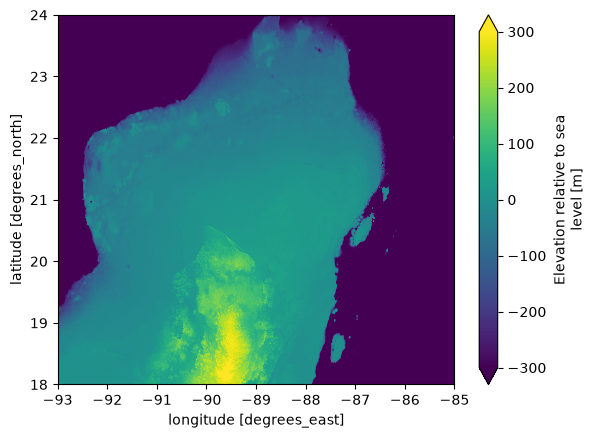

In [30]:
datos["elevation"].plot(vmin=-300, vmax=300)

## 6. Perfil
El perfil a lo largo de la latitud 20.5, de longitud -93 a -85, cruza más y Tierra, así que debe de mostrar valores negativos y positivos.

a) Grafiquen el perfil de elevación

Latitud de la malla: 20.49791666666667


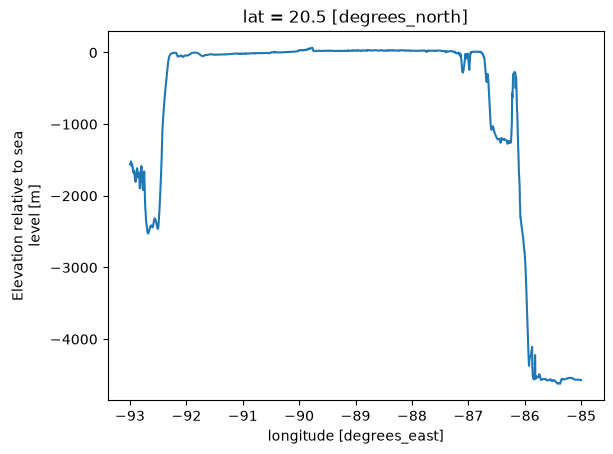

In [31]:
perfil = datos["elevation"].sel(lat=20.5, method="nearest")

print("Latitud de la malla:", float(perfil.lat.values))
perfil.plot()

b) ¿Cuál es la profundidad máxima en tierra y a qué longitud?

In [32]:
print("Altura maxima:", float(perfil.max()))
print("Longitud:", float(perfil.idxmax("lon")))

Altura maxima: 67.0
Longitud: -89.76875


c) ¿Cuál es la profundidad máxima del lado del Golfo y del lado del Caribe?

In [33]:
lado_golfo = perfil.sel(lon=slice(-93, -90.5))
lado_caribe = perfil.sel(lon=slice(-87.2, -85))

print("Golfo:", float(lado_golfo.min()))
print("Caribe:", float(lado_caribe.min()))

Golfo: -2527.0
Caribe: -4622.0


d) Grafiquen el perfil con solo los puntos de menos de 200m de profundidad. Con esa gráfica, ¿en qué longitudes aproximadas están las costas?

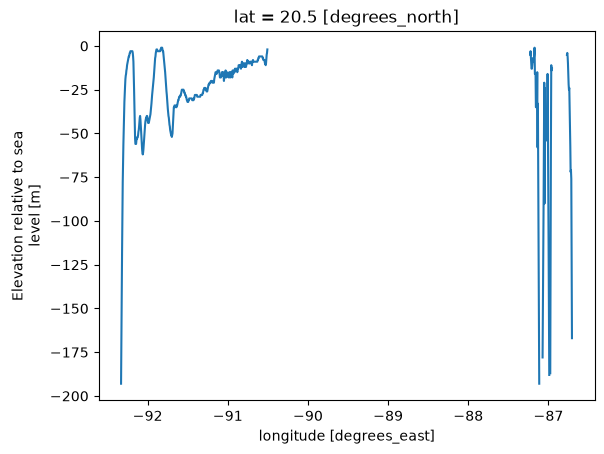

In [34]:
poco_profundos = perfil.where((perfil < 0) & (perfil > -200))
poco_profundos.plot()

Las costas son los bordes de ese hueco:

Costa del Golfo, aproximadamente en −90.00.
Costa del Caribe, aproximadamente en −87.3.

e) Consideren como plataforma continental la zona del mar con menos de 200m de profundidad. Con la gráfica del inciso anterior, ¿de qué lado de la peninsula es más ancha?

Del lado del Golfo